# Paper 1: Henderson et al. (2020) — Quanvolutional Neural Networks on Fashion-MNIST
### *"Quanvolutional Neural Networks: Powering Image Recognition with Quantum Circuits"* (arXiv:1904.04767)

---

## 1. Experimental Overview (Fashion-MNIST 10-Class)
Extending the Quanvolutional framework from handwritten digits (MNIST) [cite: 23] to complex clothing items (Fashion-MNIST) [cite: 9] across all 10 classes.

### Methodological Highlights:
1. **Qubit Allocation ($N_{\text{qubits}} = 4$):**
   - Fashion-MNIST shares the exact $28 \times 28$ spatial resolution [cite: 7, 27].
   - A $2 \times 2$ sliding window captures 4 local pixels $[x_0, x_1, x_2, x_3]$ mapped to 4 qubit wires ($2^4 = 16$-dim Hilbert space) [cite: 22, 25].
   - A stride of 2 yields an output feature map of $(28 / 2) \times (28 / 2) = 14 \times 14$ [cite: 22].
2. **Feature Extraction:**
   - Fixed random quantum circuit with closed CNOT ring measuring local expectation values $\langle Z_j \rangle$ yielding 4 channels ($14 \times 14 \times 4$) [cite: 22].
3. **Three-Way Capacity-Matched Benchmark:**
   - **Model 1 (Quantum Hybrid):** Quantum feature extractor $\to$ 2-layer CNN [cite: 22].
   - **Model 2 (Classical Random Control):** Fixed $\tanh(Wx + b)$ projection $\to$ identical 2-layer CNN [cite: 22].
   - **Model 3 (End-to-End Classical Baseline):** Raw $28 \times 28$ input $\to$ capacity-matched 2-layer CNN [cite: 22].
4. **Optimization Dynamics:** Adam vs. SGD-Momentum (0.9) vs. RMSprop.

### Step 0: Environment Setup

In [1]:
!pip install pennylane torch torchvision matplotlib scipy


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


### Step 1: Simulator Device & Setup

In [2]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt

import pennylane as qml
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets, transforms

np.random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Device: {device}")

n_qubits = 4
n_layers = 1
dev = qml.device("default.qubit", wires=n_qubits)

rand_params = np.random.uniform(0.0, 2.0 * np.pi, size=(n_layers, n_qubits))
CLASSICAL_RAND_WEIGHT = np.random.randn(4, 4).astype(np.float32)
CLASSICAL_RAND_BIAS = np.random.randn(4).astype(np.float32)

Device: mps


### Step 2: Quantum Circuit & Quanvolution Kernel

In [3]:
@qml.qnode(dev, interface="autograd")
def quanv_circuit_expval(inputs):
    for j in range(n_qubits):
        qml.RY(np.pi * inputs[j], wires=j)
    for layer in range(n_layers):
        for j in range(n_qubits):
            qml.RY(rand_params[layer, j], wires=j)
        qml.CNOT(wires=[0, 1])
        qml.CNOT(wires=[1, 2])
        qml.CNOT(wires=[2, 3])
        qml.CNOT(wires=[3, 0])
    return [qml.expval(qml.PauliZ(j)) for j in range(n_qubits)]

def quanvolve(image):
    h, w = image.shape[0], image.shape[1]
    out = np.zeros((h // 2, w // 2, 4), dtype=np.float32)
    for j in range(0, h, 2):
        for k in range(0, w, 2):
            patch = [float(image[j, k]), float(image[j, k+1]), float(image[j+1, k]), float(image[j+1, k+1])]
            q_results = quanv_circuit_expval(patch)
            for c in range(4):
                out[j // 2, k // 2, c] = float(q_results[c])
    return out

def classical_random_convolve(image):
    h, w = image.shape[0], image.shape[1]
    out = np.zeros((h // 2, w // 2, 4), dtype=np.float32)
    for j in range(0, h, 2):
        for k in range(0, w, 2):
            patch = np.array([image[j, k], image[j, k+1], image[j+1, k], image[j+1, k+1]], dtype=np.float32)
            out[j // 2, k // 2] = np.tanh(CLASSICAL_RAND_WEIGHT @ patch + CLASSICAL_RAND_BIAS)
    return out

### Step 3: Fashion-MNIST Dataset Loading & Precomputation

In [4]:
transform = transforms.Compose([transforms.ToTensor()])
train_ds = datasets.FashionMNIST(root="./data_fashion", train=True, download=True, transform=transform)
test_ds = datasets.FashionMNIST(root="./data_fashion", train=False, download=True, transform=transform)

N_TRAIN = 2000
N_TEST = 500

train_images = train_ds.data[:N_TRAIN].numpy().astype(np.float32) / 255.0
train_labels = train_ds.targets[:N_TRAIN].numpy()
test_images = test_ds.data[:N_TEST].numpy().astype(np.float32) / 255.0
test_labels = test_ds.targets[:N_TEST].numpy()

cache_dir = "./cache_fashion_quanv"
os.makedirs(cache_dir, exist_ok=True)

q_tr_path = os.path.join(cache_dir, f"q_train_{N_TRAIN}.npy")
q_te_path = os.path.join(cache_dir, f"q_test_{N_TEST}.npy")
c_tr_path = os.path.join(cache_dir, f"c_train_{N_TRAIN}.npy")
c_te_path = os.path.join(cache_dir, f"c_test_{N_TEST}.npy")

if os.path.exists(q_tr_path) and os.path.exists(q_te_path):
    print("Loading cached quantum features...")
    q_train_images = np.load(q_tr_path)
    q_test_images = np.load(q_te_path)
else:
    print(f"Precomputing quantum features for {N_TRAIN} train images...")
    t0 = time.time()
    q_train_images = np.array([quanvolve(img) for img in train_images], dtype=np.float32)
    print(f"Precomputing quantum features for {N_TEST} test images...")
    q_test_images = np.array([quanvolve(img) for img in test_images], dtype=np.float32)
    np.save(q_tr_path, q_train_images)
    np.save(q_te_path, q_test_images)

if os.path.exists(c_tr_path) and os.path.exists(c_te_path):
    print("Loading cached classical random control features...")
    c_train_images = np.load(c_tr_path)
    c_test_images = np.load(c_te_path)
else:
    print("Precomputing classical random control features...")
    c_train_images = np.array([classical_random_convolve(img) for img in train_images], dtype=np.float32)
    c_test_images = np.array([classical_random_convolve(img) for img in test_images], dtype=np.float32)
    np.save(c_tr_path, c_train_images)
    np.save(c_te_path, c_test_images)

print(f"Fashion-MNIST feature maps ready. Shape: {q_train_images.shape}")

100%|██████████| 26.4M/26.4M [00:03<00:00, 7.01MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 153kB/s]
100%|██████████| 4.42M/4.42M [00:04<00:00, 898kB/s] 
100%|██████████| 5.15k/5.15k [00:00<00:00, 29.9MB/s]


Precomputing quantum features for 2000 train images...
Precomputing quantum features for 500 test images...
Precomputing classical random control features...
Fashion-MNIST feature maps ready. Shape: (2000, 14, 14, 4)


### Step 4: Capacity-Matched Neural Networks

In [5]:
class HybridClassifierV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=4, out_channels=16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(16 * 7 * 7, 64)
        self.fc2 = nn.Linear(64, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

class ClassicalBaselineClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=2, padding=1)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(16 * 7 * 7, 64)
        self.fc2 = nn.Linear(64, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

p_hyb = sum(p.numel() for p in HybridClassifierV2().parameters())
p_base = sum(p.numel() for p in ClassicalBaselineClassifier().parameters())
print(f"Capacity Matching: Hybrid = {p_hyb} params | Classical Baseline = {p_base} params")

Capacity Matching: Hybrid = 53802 params | Classical Baseline = 53370 params


### Step 5: Training Routine

In [6]:
q_tr_tensor = torch.tensor(q_train_images.transpose(0, 3, 1, 2), dtype=torch.float32)
q_te_tensor = torch.tensor(q_test_images.transpose(0, 3, 1, 2), dtype=torch.float32)
c_tr_tensor = torch.tensor(c_train_images.transpose(0, 3, 1, 2), dtype=torch.float32)
c_te_tensor = torch.tensor(c_test_images.transpose(0, 3, 1, 2), dtype=torch.float32)
raw_tr_tensor = torch.tensor(train_images[:, np.newaxis, :, :], dtype=torch.float32)
raw_te_tensor = torch.tensor(test_images[:, np.newaxis, :, :], dtype=torch.float32)
y_tr_tensor = torch.tensor(train_labels, dtype=torch.long)
y_te_tensor = torch.tensor(test_labels, dtype=torch.long)

BATCH_SIZE = 32
q_tr_loader = DataLoader(TensorDataset(q_tr_tensor, y_tr_tensor), batch_size=BATCH_SIZE, shuffle=True)
q_te_loader = DataLoader(TensorDataset(q_te_tensor, y_te_tensor), batch_size=BATCH_SIZE, shuffle=False)
c_tr_loader = DataLoader(TensorDataset(c_tr_tensor, y_tr_tensor), batch_size=BATCH_SIZE, shuffle=True)
c_te_loader = DataLoader(TensorDataset(c_te_tensor, y_te_tensor), batch_size=BATCH_SIZE, shuffle=False)
raw_tr_loader = DataLoader(TensorDataset(raw_tr_tensor, y_tr_tensor), batch_size=BATCH_SIZE, shuffle=True)
raw_te_loader = DataLoader(TensorDataset(raw_te_tensor, y_te_tensor), batch_size=BATCH_SIZE, shuffle=False)

def train_model(model, train_loader, test_loader, epochs=30, lr=0.001, opt_name="Adam", device=device):
    model = model.to(device)
    if opt_name == "Adam":
        opt = torch.optim.Adam(model.parameters(), lr=lr)
    elif opt_name == "SGD_Momentum":
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    elif opt_name == "RMSprop":
        opt = torch.optim.RMSprop(model.parameters(), lr=lr)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr)

    crit = nn.CrossEntropyLoss()
    history = {"loss": [], "train_acc": [], "test_acc": [], "gap": []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct_tr, total_tr = 0.0, 0, 0
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            opt.zero_grad()
            out = model(bx)
            loss = crit(out, by)
            loss.backward()
            opt.step()
            running_loss += loss.item() * bx.size(0)
            correct_tr += (out.argmax(dim=1) == by).sum().item()
            total_tr += bx.size(0)

        model.eval()
        correct_te, total_te = 0, 0
        with torch.no_grad():
            for bx, by in test_loader:
                bx, by = bx.to(device), by.to(device)
                pred = model(bx).argmax(dim=1)
                correct_te += (pred == by).sum().item()
                total_te += bx.size(0)

        train_acc = correct_tr / total_tr
        test_acc = correct_te / total_te
        gap = train_acc - test_acc

        history["loss"].append(running_loss / total_tr)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)
        history["gap"].append(gap)
    return history

### Step 6: Optimizer Dynamics Benchmark on Fashion-MNIST

In [7]:
opt_list = ["Adam", "SGD_Momentum", "RMSprop"]
opt_results = {}
OPT_EPOCHS = 20

print(f"Evaluating Optimizer Dynamics on Fashion-MNIST Quanvolutional Hybrid ({OPT_EPOCHS} epochs)...")
for opt_name in opt_list:
    torch.manual_seed(42)
    m = HybridClassifierV2()
    h = train_model(m, q_tr_loader, q_te_loader, epochs=OPT_EPOCHS, lr=0.001, opt_name=opt_name)
    opt_results[opt_name] = h
    print(f"  Optimizer: {opt_name:<14} | Final Train Acc: {h['train_acc'][-1]*100:.2f}% | Final Test Acc: {h['test_acc'][-1]*100:.2f}%")

Evaluating Optimizer Dynamics on Fashion-MNIST Quanvolutional Hybrid (20 epochs)...
  Optimizer: Adam           | Final Train Acc: 90.25% | Final Test Acc: 78.80%
  Optimizer: SGD_Momentum   | Final Train Acc: 68.45% | Final Test Acc: 63.80%
  Optimizer: RMSprop        | Final Train Acc: 93.75% | Final Test Acc: 78.60%


### Step 7: Multi-Seed Benchmark across Three Models

In [8]:
EPOCHS = 30
NUM_SEEDS = 3
RUN_SEEDS = [42, 43, 44][:NUM_SEEDS]

q_accs, cr_accs, base_accs = [], [], []
q_gaps, cr_gaps, base_gaps = [], [], []
q_hist_list, cr_hist_list, base_hist_list = [], [], []

print(f"Running 3 Models on Fashion-MNIST over {NUM_SEEDS} Seeds...")
for s in RUN_SEEDS:
    # 1. Quantum Hybrid
    torch.manual_seed(s)
    m_q = HybridClassifierV2()
    hq = train_model(m_q, q_tr_loader, q_te_loader, epochs=EPOCHS, lr=0.001, opt_name="Adam")
    q_accs.append(hq["test_acc"][-1])
    q_gaps.append(hq["gap"][-1])
    q_hist_list.append(hq)

    # 2. Classical Random Control
    torch.manual_seed(s)
    m_cr = HybridClassifierV2()
    hcr = train_model(m_cr, c_tr_loader, c_te_loader, epochs=EPOCHS, lr=0.001, opt_name="Adam")
    cr_accs.append(hcr["test_acc"][-1])
    cr_gaps.append(hcr["gap"][-1])
    cr_hist_list.append(hcr)

    # 3. Classical Baseline
    torch.manual_seed(s)
    m_base = ClassicalBaselineClassifier()
    hbase = train_model(m_base, raw_tr_loader, raw_te_loader, epochs=EPOCHS, lr=0.001, opt_name="Adam")
    base_accs.append(hbase["test_acc"][-1])
    base_gaps.append(hbase["gap"][-1])
    base_hist_list.append(hbase)
    print(f"  Seed {s} -> Quantum: {hq['test_acc'][-1]*100:.2f}% | Class. Rand: {hcr['test_acc'][-1]*100:.2f}% | Baseline: {hbase['test_acc'][-1]*100:.2f}%")

Running 3 Models on Fashion-MNIST over 3 Seeds...
  Seed 42 -> Quantum: 78.20% | Class. Rand: 83.80% | Baseline: 85.60%
  Seed 43 -> Quantum: 78.60% | Class. Rand: 84.40% | Baseline: 82.60%
  Seed 44 -> Quantum: 80.20% | Class. Rand: 85.60% | Baseline: 82.20%


### Step 8: Summary Table and Generalization Plots

THREE-WAY FASHION-MNIST EMPIRICAL BENCHMARK (3 SEEDS)
Model Architecture                   | Params   | Test Accuracy (%)    | Generalization Gap
----------------------------------------------------------------------------------------
1. Quanvolutional Hybrid (Quantum + CNN) | 53802    | 79.00 ± 0.86%       | +17.90 ± 0.44%
2. Classical Random Control (tanh + CNN) | 53802    | 84.60 ± 0.75%       | +9.53 ± 1.12%
3. Classical Baseline (Raw Pixels + CNN) | 53370    | 83.47 ± 1.52%       | +10.67 ± 2.10%


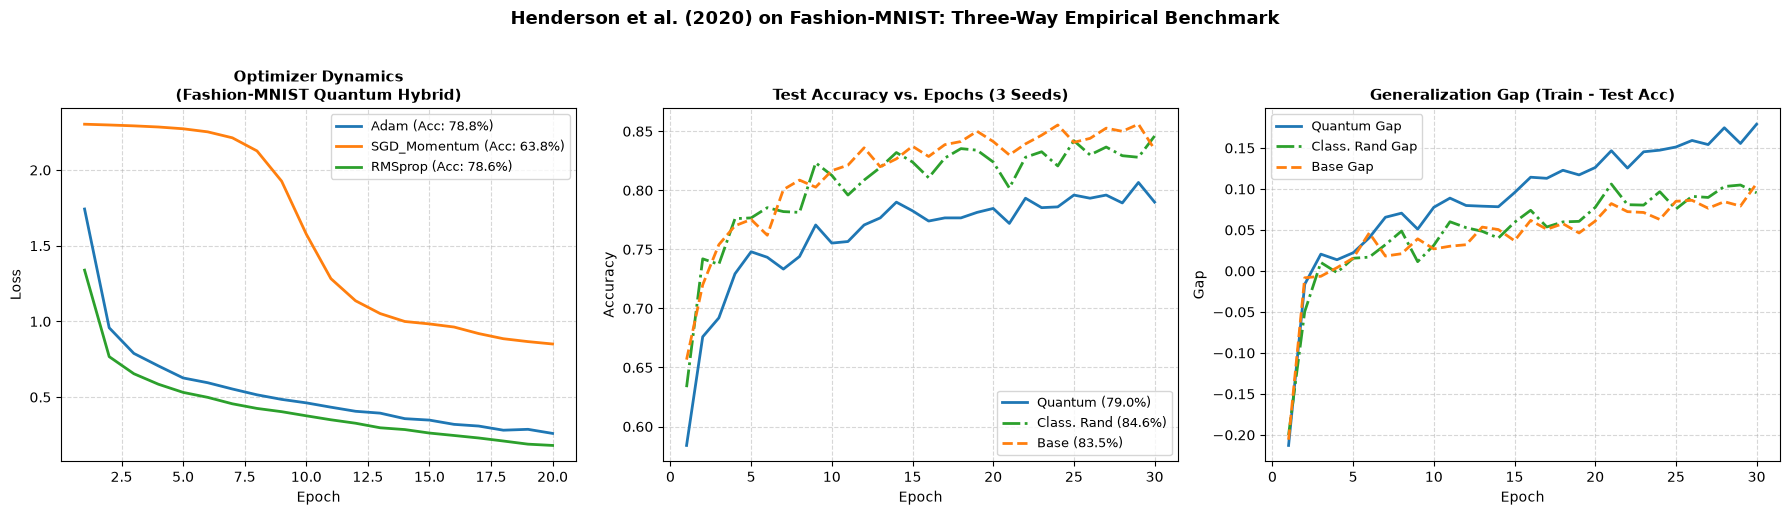

In [9]:
print("=" * 88)
print(f"THREE-WAY FASHION-MNIST EMPIRICAL BENCHMARK ({NUM_SEEDS} SEEDS)")
print(f"{'Model Architecture':<36} | {'Params':<8} | {'Test Accuracy (%)':<20} | {'Generalization Gap':<16}")
print("-" * 88)
print(f"{'1. Quanvolutional Hybrid (Quantum + CNN)':<36} | {p_hyb:<8} | "
      f"{np.mean(q_accs)*100:.2f} ± {np.std(q_accs)*100:.2f}%{'':<6} | "
      f"{np.mean(q_gaps)*100:+.2f} ± {np.std(q_gaps)*100:.2f}%")
print(f"{'2. Classical Random Control (tanh + CNN)':<36} | {p_hyb:<8} | "
      f"{np.mean(cr_accs)*100:.2f} ± {np.std(cr_accs)*100:.2f}%{'':<6} | "
      f"{np.mean(cr_gaps)*100:+.2f} ± {np.std(cr_gaps)*100:.2f}%")
print(f"{'3. Classical Baseline (Raw Pixels + CNN)':<36} | {p_base:<8} | "
      f"{np.mean(base_accs)*100:.2f} ± {np.std(base_accs)*100:.2f}%{'':<6} | "
      f"{np.mean(base_gaps)*100:+.2f} ± {np.std(base_gaps)*100:.2f}%")
print("=" * 88)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
epochs_arr = np.arange(1, EPOCHS + 1)

# Panel 1: Optimizers
for opt_name, h in opt_results.items():
    axes[0].plot(np.arange(1, OPT_EPOCHS + 1), h["loss"], lw=2, label=f"{opt_name} (Acc: {h['test_acc'][-1]*100:.1f}%)")
axes[0].set_title("Optimizer Dynamics\n(Fashion-MNIST Quantum Hybrid)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Epoch", fontsize=10); axes[0].set_ylabel("Loss", fontsize=10)
axes[0].grid(True, linestyle="--", alpha=0.5); axes[0].legend(fontsize=9)

# Panel 2: Test Accuracy
axes[1].plot(epochs_arr, np.mean([h["test_acc"] for h in q_hist_list], axis=0), color="#1f77b4", lw=2, label=f"Quantum ({np.mean(q_accs)*100:.1f}%)")
axes[1].plot(epochs_arr, np.mean([h["test_acc"] for h in cr_hist_list], axis=0), color="#2ca02c", lw=2, linestyle="-.", label=f"Class. Rand ({np.mean(cr_accs)*100:.1f}%)")
axes[1].plot(epochs_arr, np.mean([h["test_acc"] for h in base_hist_list], axis=0), color="#ff7f0e", lw=2, linestyle="--", label=f"Base ({np.mean(base_accs)*100:.1f}%)")
axes[1].set_title(f"Test Accuracy vs. Epochs ({NUM_SEEDS} Seeds)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Epoch", fontsize=10); axes[1].set_ylabel("Accuracy", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.5); axes[1].legend(fontsize=9)

# Panel 3: Overfitting Gap
axes[2].plot(epochs_arr, np.mean([h["gap"] for h in q_hist_list], axis=0), color="#1f77b4", lw=2, label="Quantum Gap")
axes[2].plot(epochs_arr, np.mean([h["gap"] for h in cr_hist_list], axis=0), color="#2ca02c", lw=2, linestyle="-.", label="Class. Rand Gap")
axes[2].plot(epochs_arr, np.mean([h["gap"] for h in base_hist_list], axis=0), color="#ff7f0e", lw=2, linestyle="--", label="Base Gap")
axes[2].set_title("Generalization Gap (Train - Test Acc)", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Epoch", fontsize=10); axes[2].set_ylabel("Gap", fontsize=10)
axes[2].grid(True, linestyle="--", alpha=0.5); axes[2].legend(fontsize=9)

plt.suptitle("Henderson et al. (2020) on Fashion-MNIST: Three-Way Empirical Benchmark", fontsize=13, y=1.02, fontweight="bold")
plt.tight_layout()
plt.show()